# 03 Weather data

Day-ahead weather forecasts from Open-Meteo's Previous Runs API ("previous day 1"), for three locations:
- Adelaide: temperature, solar, cloud (demand and rooftop solar)
- Snowtown and Hallett: wind at 100 m (wind farm areas)

Goal: check the data, line it up with the 5-minute prices, and save a clean file for the model notebook.

In [1]:
from pathlib import Path
import pandas as pd

LOCATIONS = ["adelaide", "snowtown", "hallett"]

In [6]:
raw = {
    name: pd.read_csv(f"../data/weather/{name}.csv", parse_dates=["time"]) for name in LOCATIONS
                      }
for name, w in raw.items():
    print(name, w.shape, w["time"].min(), w["time"].max())

adelaide (16080, 5) 2024-01-01 00:00:00 2025-10-31 23:00:00
snowtown (16080, 5) 2024-01-01 00:00:00 2025-10-31 23:00:00
hallett (16080, 5) 2024-01-01 00:00:00 2025-10-31 23:00:00


In [11]:
for name, w in raw.items():
    for col in w.columns[1:]:
        missing = w.loc[w[col].isna(), "time"]
        print(f"{name:10} {col:35} {len(missing):5} missing, lastmissing: {missing.max()}")

adelaide   temperature_2m_previous_day1          454 missing, lastmissing: 2024-01-19 21:00:00
adelaide   windspeed_100m_previous_day1         1120 missing, lastmissing: 2024-02-16 15:00:00
adelaide   shortwave_radiation_previous_day1     454 missing, lastmissing: 2024-01-19 21:00:00
adelaide   cloud_cover_previous_day1             454 missing, lastmissing: 2024-01-19 21:00:00
snowtown   temperature_2m_previous_day1          454 missing, lastmissing: 2024-01-19 21:00:00
snowtown   windspeed_100m_previous_day1         1120 missing, lastmissing: 2024-02-16 15:00:00
snowtown   shortwave_radiation_previous_day1     454 missing, lastmissing: 2024-01-19 21:00:00
snowtown   cloud_cover_previous_day1             454 missing, lastmissing: 2024-01-19 21:00:00
hallett    temperature_2m_previous_day1          454 missing, lastmissing: 2024-01-19 21:00:00
hallett    windspeed_100m_previous_day1         1120 missing, lastmissing: 2024-02-16 15:00:00
hallett    shortwave_radiation_previous_day1     4

## Missing values

All missing values are at the start of the data, with no gaps afterwards. Open-Meteo's archive of previous runs started later than 1 Jan 2024:
- Temperature, solar and cloud start on 19 Jan 2024 at 22:00
- Wind at 100 m starts on 16 Feb 2024 at 16:00

All three locations are the same. I'll start the M2 data on 17 Feb 2024, the first full day where everything exists.

In [12]:
START = "2024-02-17"

frames = []
for name, w in raw.items():
    w = w.set_index("time")
    w.columns = [
        f"{name}_{c.replace('_previous_day1', '').replace('windspeed', 'wind_speed')}"
        for c in w.columns
    ]
    frames.append(w)

weather = pd.concat(frames, axis=1).loc[START:]

assert weather.isna().sum().sum() == 0, "Unexpected missing values after trimming"
print(weather.shape)
weather.head()

(14952, 12)


,adelaide_temperature_2m,adelaide_wind_speed_100m,adelaide_shortwave_radiation,adelaide_cloud_cover,snowtown_temperature_2m,snowtown_wind_speed_100m,snowtown_shortwave_radiation,snowtown_cloud_cover,hallett_temperature_2m,hallett_wind_speed_100m,hallett_shortwave_radiation,hallett_cloud_cover
time,,,,,,,,,,,,
2024-02-17 00:00:00,19.8,20.2,0.0,0.0,18.7,16.2,0.0,0.0,18.9,22.6,0.0,0.0
2024-02-17 01:00:00,19.2,18.4,0.0,0.0,17.4,15.5,0.0,0.0,17.6,21.2,0.0,0.0
2024-02-17 02:00:00,18.8,16.1,0.0,0.0,16.6,14.2,0.0,0.0,16.3,20.2,0.0,0.0
2024-02-17 03:00:00,18.3,15.4,0.0,10.0,16.1,14.5,0.0,0.0,15.2,19.8,0.0,0.0
2024-02-17 04:00:00,17.3,15.0,0.0,4.0,14.8,14.9,0.0,13.0,14.4,21.2,0.0,0.0


In [16]:
files = sorted(Path("../data/raw").glob("*.csv"))
prices = (
    pd.concat(pd.read_csv(f, parse_dates=["SETTLEMENTDATE"]) for f in files)
    .set_index("SETTLEMENTDATE")
    .sort_index()
    .loc[f"{START} 0:05":, ["RRP", "TOTALDEMAND"]]
)
print(prices.shape)

(179424, 2)


In [20]:
weather_5min = (
    weather.reindex(weather.index.union(prices.index))
    .interpolate(method="time")
    .ffill()
    .reindex(prices.index)
)

assert weather_5min.index.equals(prices.index), "Weather and Prices don't line up"
assert weather_5min.isna().sum().sum() == 0
print(weather_5min.shape)

(179424, 12)


## Does wind explain the evenings?

In M1 the baseline's biggest errors were evenings where prices stayed near 0. My guess was wind. Checking that here before building a model on it.

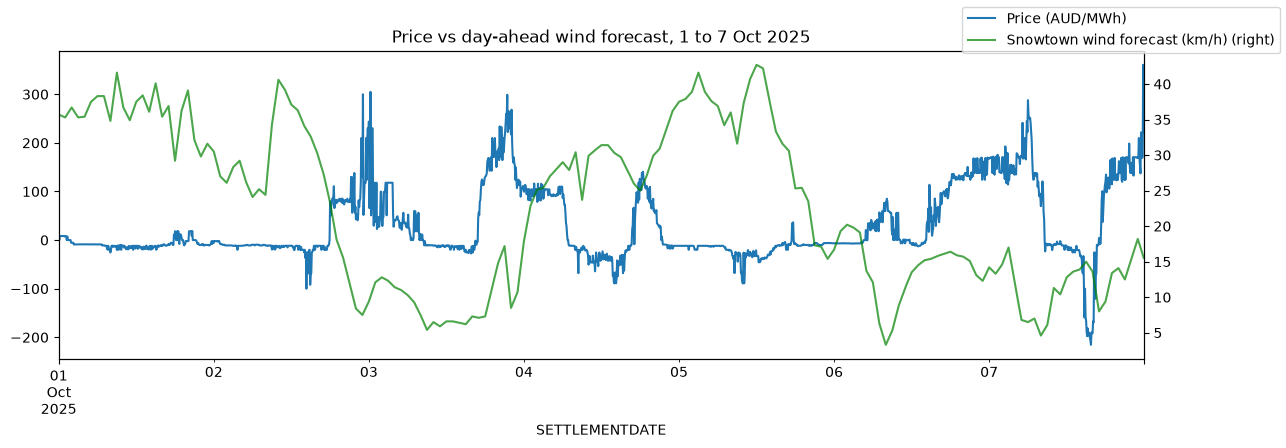

In [21]:
week = slice("2025-10-01", "2025-10-07")
ax = prices.loc[week, "RRP"].plot(figsize=(14, 4), label="Price (AUD/MWh)")
weather_5min.loc[week, "snowtown_wind_speed_100m"].plot(
    ax=ax, secondary_y=True, color="green", alpha=0.7, label="Snowtown wind forecast (km/h)"
)
ax.set_title("Price vs day-ahead wind forecast, 1 to 7 Oct 2025")
ax.figure.legend();

In [22]:
combined = prices.join(weather_5min)
evening = combined[combined.index.hour.isin([17, 18, 19, 20])]

wind_group = pd.qcut(evening["snowtown_wind_speed_100m"], 4, labels=["calmest 25%", "low", "high", "windiest 25%"])
evening.groupby(wind_group, observed=True)["RRP"].median()

snowtown_wind_speed_100m
calmest 25%     189.09
low             152.27
high            122.65
windiest 25%     81.18
Name: RRP, dtype: float64

In [23]:
Path("../data/processed").mkdir(exist_ok=True)
weather_5min.to_csv("../data/processed/weather.csv")

## Summary

*Prices in AUD/MWh. Wind is the day-ahead forecast at 100 m, in km/h.*

**Finding:** The day-ahead wind forecast explains a lot of the evening price swings the baseline got wrong. The windier the forecast, the cheaper the evening.

**Evidence:**
- Splitting all evenings (17:00 to 20:59) into four groups by forecast wind at Snowtown, the median price drops steadily: 189 for the calmest 25%, 152, 123, and 81 for the windiest 25%.
- In the first week of Oct 2025, the evenings where prices stayed near 0 (Oct 1 and Oct 5) had high wind forecasts, and the evenings with spikes (Oct 3 and Oct 7) had low ones.
- Weather data is complete from 17 Feb 2024 after trimming, and lines up exactly with the 5-minute prices.

**What this means:**
- Wind forecasts should be one of the most useful features in M2.
- Wind isn't the whole story. Even the windiest evenings have a median of 81, so solar, temperature and other factors still matter.
- The model needs to learn that wind matters most in the evening. During the day, solar already pushes prices down. A tree model like LightGBM can learn this kind of interaction by itself.